# TESE UFMG — COMPARAÇÃO DE 4 PARADIGMAS EM UROCULTURA (COM GRAM vs. SEM GRAM)

**Desenho metodológico congelado (sem vazamento):**
- **Base:** `UROT_UROC_GG_Base_Definitiva_2011_2024_2026-10-19.csv.gz` (`sep=";"`)
- **Desenvolvimento:** 2011–2022 com *Nested Cross-Validation* **5 × 3** (`StratifiedGroupKFold` agrupado por `Paciente_ID`)
- **Teste temporal independente:** 2023–2024 (apenas pacientes novos não vistos até 2022)
- **4 paradigmas (um de cada família):** `ElasticNet`, `RandomForest`, `HistGradientBoosting` e `TabResNet` (PyTorch)
- **Preditores fisiológicos do EAS (9) + Demografia/Contexto (3):**
  - `UROT__PH`, `UROT__GRAVID` (+ `UROT__GRAVID_DESVIO_QUAD`), `UROT__GLIC`, `UROT__SEDHEM`, **hemoglobina na fita** (`UROT__HEMOGL` / detecção automática), `UROT__SEDLEU`, `UROT__ESTERASE`, `UROT__FLORA`, `UROT__NITRIT`
  - `Idade_anos`, `Sexo`, `Origem`
- **Dois braços executados automaticamente:**
  1. `EAS_SEM_GRAM`: variáveis fisiológicas do EAS + demografia/origem
  2. `EAS_COM_GRAM`: variáveis fisiológicas do EAS + demografia/origem + **4 marcadores tintoriais/morfológicos do Gram** (`gram_bacterias_presentes`, `gram_bgn`, `gram_cgp`, `gram_levedura`, sem quantificação)
- **Saídas geradas (exibidas no Colab e salvas no Google Drive em 300 DPI):**
  - Tabelas formatadas (CSV + Excel multi-abas `Tabelas_Consolidadas_2023_2024.xlsx`)
  - `01_Curvas_ROC_PR_2023_2024.png`: Curvas ROC e Precisão–Revocação dos 4 paradigmas (sem Gram e com Gram)
  - `02_Comparacao_AUROC_PRAUC_Com_vs_Sem_Gram.png`: Comparação direta com IC 95% e ganho pareado (ΔAUROC / ΔPR-AUC e *p*)
  - `03_Calibracao_Probabilistica_2023_2024.png`: Curvas de calibração (*reliability diagrams*) dos 4 paradigmas
  - `04_Curva_Decisao_DCA_2023_2024.png`: Análise de Curva de Decisão (Benefício Líquido)
  - `05_Importancia_Permutacao_2023_2024.png` e `06_SHAP_Beeswarm_*.png` / `06_SHAP_Barras_*.png`: Explicabilidade do modelo líder


## 0. Preparo do ambiente e importações (instala `shap` se necessário)


In [ ]:
# Opcional no Colab: garante shap e openpyxl para gráficos SHAP e planilha Excel
import importlib.util, subprocess, sys

for pkg in ["shap", "openpyxl"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import json
import re
import time
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from torch.utils.data import DataLoader, TensorDataset

from google.colab import drive
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import ParameterGrid, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

mpl.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 8.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def log(msg: str) -> None:
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)


## 1. Configuração central e lista de preditores fisiológicos


In [ ]:
CONFIG = {
    "input_path": "/content/drive/MyDrive/Todos os arquivos GPT/UROT_UROC_GG_Base_Definitiva_2011_2024_2026-10-19.csv.gz",
    "sep": ";",
    "output_dir": "/content/drive/MyDrive/Todos os arquivos GPT/resultados_tese_4paradigmas_2023_2024",
    "col_target": "Cultura_positiva",
    "col_group": "Paciente_ID",
    "col_year": "Ano",
    "col_gram_text": "Gram_texto",
    "arms": [
        {"name": "EAS_SEM_GRAM", "incluir_gram": False},
        {"name": "EAS_COM_GRAM", "incluir_gram": True},
    ],
    "train_max_year": 2022,
    "test_years": [2023, 2024],
    "exclude_seen_patients_in_test": True,
    "outer_splits": 5,
    "inner_splits": 3,
    "n_bootstrap": 1000,
    "target_high_sens": 0.95,
    "shap_sample_size": 2000,
    "random_state": 42,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}

NUMERIC_BASE_FEATURES = [
    "Idade_anos",
    "UROT__GRAVID",
    "UROT__GRAVID_DESVIO_QUAD",
    "UROT__PH",
    "UROT__GLIC",
    "UROT__SEDHEM",
    "UROT__SEDLEU",
    "UROT__ESTERASE",
    "UROT__FLORA",
]

HEMOGL_CANDIDATES = [
    "UROT__HEMOGL",
    "UROT__HEMOGLOBINA",
    "UROT__HEMOG",
    "UROT__HB",
    "UROT__SANGUE",
    "HEMOGL",
]

CATEGORICAL_FEATURES = [
    "Sexo",
    "Origem",
    "UROT__NITRIT",
]

GRAM_STRUCTURED_FEATURES = [
    "gram_bacterias_presentes",
    "gram_bgn",
    "gram_cgp",
    "gram_levedura",
]

FORBIDDEN_SUBSTRINGS = (
    "UROC", "CONTAGEM", "CULTURA", "REVISAO", "PENDEN", "CONFLITO",
    "ALERTA", "RECUPERAC", "FONTE", "LAUDO", "ISOLADO", "RESUL", "ATB", "MIC_"
)

MODEL_COLORS = {
    "ElasticNet": "#1f77b4",
    "RandomForest": "#2ca02c",
    "HistGradientBoosting": "#d62728",
    "TabResNet": "#9467bd",
}


## 2. Harmonização clínica (EAS fisiológico + hemoglobina na fita + Gram morfológico)


In [ ]:
def parse_densidade(val) -> float:
    if pd.isna(val):
        return np.nan
    s = str(val).strip().upper().replace(",", ".")
    m = re.search(r"(\d+(?:\.\d+)?)", s)
    if not m:
        return np.nan
    num = float(m.group(1))
    if 1000.0 <= num <= 1060.0:
        num = num / 1000.0
    if 1.000 <= num <= 1.060:
        return num
    return np.nan


def parse_sedimento(val) -> float:
    if pd.isna(val):
        return np.nan
    s = str(val).strip().upper()
    if any(w in s for w in ["AUSENT", "NEGAT", "RARO"]):
        return 0.0
    if "NUMEROS" in s or "MACIC" in s or "INCONT" in s:
        return 100.0
    m = re.search(r"(\d+(?:[.,]\d+)?)", s)
    return float(m.group(1).replace(",", ".")) if m else np.nan


MAPA_CRUZES = {
    "NEGATIVO": 0.0, "NEGATIVA": 0.0, "AUSENTE": 0.0, "NORMAL": 0.0, "NAO REAGENTE": 0.0,
    "TRACOS": 0.5, "TRAÇOS": 0.5, "TRACO": 0.5, "TRAÇO": 0.5, "VESTIGIOS": 0.5, "VESTÍGIOS": 0.5,
    "ESCASSA": 1.0, "ESCASSO": 1.0, "1+": 1.0, "+": 1.0, "LEVE": 1.0, "DISCRETA": 1.0, "DISCRETO": 1.0, "POSITIVO": 1.0,
    "2+": 2.0, "++": 2.0, "MODERADA": 2.0, "MODERADO": 2.0,
    "3+": 3.0, "+++": 3.0, "ACENTUADA": 3.0, "ACENTUADO": 3.0, "NUMEROSA": 3.0, "INTENSA": 3.0,
    "4+": 4.0, "++++": 4.0, "MACICA": 4.0, "MACIÇA": 4.0,
}


def parse_semiquantitativo(serie: pd.Series) -> pd.Series:
    s = serie.astype(str).str.strip().str.upper()
    num = pd.to_numeric(s.str.replace(",", ".", regex=False), errors="coerce")
    mapped = s.map(MAPA_CRUZES)
    return num.fillna(mapped)


def extrair_features_gram(serie_gram: pd.Series) -> pd.DataFrame:
    out = pd.DataFrame(index=serie_gram.index)
    s = serie_gram.astype(str).str.upper().str.strip()
    invalido = serie_gram.isna() | s.isin(["", "NAN", "NONE", "NAO REALIZADO", "NÃO REALIZADO"])

    negativo = s.str.contains(
        r"NAO FORAM OBSERVAD|NÃO FORAM OBSERVAD|AUSENCIA DE BACT|AUSÊNCIA DE BACT|NEGATIV",
        regex=True,
    )
    out["gram_bacterias_presentes"] = np.where(invalido, np.nan, np.where(negativo, 0.0, 1.0))
    out["gram_bgn"] = np.where(invalido, np.nan, s.str.contains(r"GRAM.?NEGATIV|BGN|BACILO", regex=True).astype(float))
    out["gram_cgp"] = np.where(invalido, np.nan, s.str.contains(r"GRAM.?POSITIV|CGP|COCO", regex=True).astype(float))
    out["gram_levedura"] = np.where(invalido, np.nan, s.str.contains(r"LEVEDUR|FUNG|PSEUDO.?HIFA|CANDIDA", regex=True).astype(float))
    return out


def detectar_coluna_hemoglobina(df: pd.DataFrame) -> str:
    for cand in HEMOGL_CANDIDATES:
        if cand in df.columns:
            return cand
    for col in df.columns:
        u = col.upper()
        if "HEMOG" in u or ("UROT" in u and ("SANG" in u or u.endswith("__HB"))):
            return col
    urot_cols = [c for c in df.columns if "UROT" in c.upper()]
    raise KeyError(
        f"Coluna de hemoglobina na fita não encontrada. Colunas UROT disponíveis: {urot_cols}"
    )


def preparar_dataframe_base(df_raw: pd.DataFrame, cfg: dict) -> tuple[pd.DataFrame, list[str], list[str], str]:
    df = df_raw.copy()
    df.columns = [c.strip() for c in df.columns]

    df[cfg["col_target"]] = pd.to_numeric(df[cfg["col_target"]], errors="coerce")
    df[cfg["col_year"]] = pd.to_numeric(df[cfg["col_year"]], errors="coerce")
    df = df.dropna(subset=[cfg["col_target"], cfg["col_group"], cfg["col_year"]]).copy()
    df[cfg["col_target"]] = df[cfg["col_target"]].astype(int)
    df[cfg["col_year"]] = df[cfg["col_year"]].astype(int)
    df[cfg["col_group"]] = df[cfg["col_group"]].astype(str).str.strip()

    df["UROT__GRAVID"] = df["UROT__GRAVID"].apply(parse_densidade)
    df["UROT__GRAVID_DESVIO_QUAD"] = (df["UROT__GRAVID"] - 1.015) ** 2

    hemogl_col = detectar_coluna_hemoglobina(df)
    log(f"Coluna de hemoglobina na fita detectada: '{hemogl_col}'")

    num_base_cols = [c for c in NUMERIC_BASE_FEATURES if c in df.columns]
    if hemogl_col not in num_base_cols:
        num_base_cols.append(hemogl_col)
    cat_cols = [c for c in CATEGORICAL_FEATURES if c in df.columns]

    for c in num_base_cols + cat_cols:
        if any(sub in c.upper() for sub in FORBIDDEN_SUBSTRINGS):
            raise ValueError(f"Coluna bloqueada por risco de vazamento: {c}")

    for col in ["Idade_anos", "UROT__PH"]:
        if col in num_base_cols:
            df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", ".", regex=False), errors="coerce")

    for col in ["UROT__SEDLEU", "UROT__SEDHEM"]:
        if col in num_base_cols:
            df[col] = df[col].apply(parse_sedimento)

    for col in ["UROT__ESTERASE", "UROT__GLIC", "UROT__FLORA", hemogl_col]:
        if col in num_base_cols:
            df[col] = parse_semiquantitativo(df[col])

    for col in cat_cols:
        s = df[col].astype(str).str.strip()
        df[col] = np.where(df[col].isna() | s.isin(["", "nan", "NaN", "None", "NONE", "<NA>"]), np.nan, s)

    if cfg["col_gram_text"] not in df.columns:
        raise KeyError(f"Coluna '{cfg['col_gram_text']}' não encontrada na base.")
    gram_df = extrair_features_gram(df[cfg["col_gram_text"]])
    for gcol in GRAM_STRUCTURED_FEATURES:
        df[gcol] = gram_df[gcol]

    return df, num_base_cols, cat_cols, hemogl_col


## 3. Arquitetura TabResNet (PyTorch compatível com scikit-learn)


In [ ]:
class ResBlockTabular(nn.Module):
    def __init__(self, dim: int, dropout: float = 0.2):
        super().__init__()
        self.block = nn.Sequential(
            nn.LayerNorm(dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(dim, dim),
            nn.LayerNorm(dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(dim, dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.block(x)


class TabResNetNet(nn.Module):
    def __init__(self, in_features: int, hidden_dim: int = 128, n_blocks: int = 2, dropout: float = 0.2):
        super().__init__()
        self.in_proj = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
        )
        self.blocks = nn.ModuleList([
            ResBlockTabular(hidden_dim, dropout=dropout) for _ in range(n_blocks)
        ])
        self.head = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.in_proj(x)
        for blk in self.blocks:
            h = blk(h)
        return self.head(h).squeeze(-1)


class TabResNetClassifier(BaseEstimator, ClassifierMixin):
    def __init__(
        self,
        hidden_dim: int = 128,
        n_blocks: int = 2,
        dropout: float = 0.2,
        lr: float = 1e-3,
        weight_decay: float = 1e-4,
        batch_size: int = 1024,
        epochs: int = 18,
        random_state: int = 42,
        device: str = "cpu",
    ):
        self.hidden_dim = hidden_dim
        self.n_blocks = n_blocks
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.epochs = epochs
        self.random_state = random_state
        self.device = device

    def _to_dense_float32(self, X):
        if hasattr(X, "toarray"):
            X = X.toarray()
        arr = np.asarray(X, dtype=np.float32)
        return np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)

        X_arr = self._to_dense_float32(X)
        y_arr = np.asarray(y, dtype=np.float32)

        dataset = TensorDataset(torch.from_numpy(X_arr), torch.from_numpy(y_arr))
        loader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.classes_ = np.array([0, 1])
        self.model_ = TabResNetNet(
            in_features=X_arr.shape[1],
            hidden_dim=self.hidden_dim,
            n_blocks=self.n_blocks,
            dropout=self.dropout,
        ).to(self.device)

        optimizer = torch.optim.AdamW(
            self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.epochs)
        criterion = nn.BCEWithLogitsLoss()

        self.model_.train()
        for _ in range(self.epochs):
            for xb, yb in loader:
                xb = xb.to(self.device)
                yb = yb.to(self.device)
                optimizer.zero_grad()
                logits = self.model_(xb)
                loss = criterion(logits, yb)
                loss.backward()
                optimizer.step()
            scheduler.step()

        return self

    def predict_proba(self, X):
        self.model_.eval()
        X_arr = self._to_dense_float32(X)
        with torch.no_grad():
            tensor_x = torch.from_numpy(X_arr).to(self.device)
            probs_pos = torch.sigmoid(self.model_(tensor_x)).cpu().numpy()
        probs_pos = np.clip(probs_pos, 1e-7, 1.0 - 1e-7)
        return np.column_stack([1.0 - probs_pos, probs_pos])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


## 4. Pré-processamento, limiares (Youden e alta sensibilidade), métricas e bootstrap pareado


In [ ]:
def build_preprocessor(num_cols: list[str], cat_cols: list[str], scale_numeric: bool = True) -> ColumnTransformer:
    num_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))

    cat_steps = [
        ("imputer", SimpleImputer(strategy="constant", fill_value="AUSENTE")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]

    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(num_steps), num_cols),
            ("cat", Pipeline(cat_steps), cat_cols),
        ],
        remainder="drop",
    )


def compute_youden_threshold(y_true: np.ndarray, y_prob: np.ndarray) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)
    thresholds = np.unique(np.quantile(y_prob, np.linspace(0.01, 0.99, 197)))
    best_j, best_th, best_sens, best_spec = -np.inf, 0.5, np.nan, np.nan

    pos_mask = y_true == 1
    neg_mask = y_true == 0
    n_pos = max(int(pos_mask.sum()), 1)
    n_neg = max(int(neg_mask.sum()), 1)

    for th in thresholds:
        pred = (y_prob >= th).astype(int)
        sens = float(((pred == 1) & pos_mask).sum()) / n_pos
        spec = float(((pred == 0) & neg_mask).sum()) / n_neg
        j = sens + spec - 1.0
        if j > best_j:
            best_j, best_th, best_sens, best_spec = j, float(th), sens, spec

    return {"threshold": best_th, "youden_j": float(best_j), "sens_at_th": best_sens, "spec_at_th": best_spec}


def compute_high_sensitivity_threshold(y_true: np.ndarray, y_prob: np.ndarray, target_sens: float = 0.95) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)
    pos_probs = np.sort(y_prob[y_true == 1])
    if len(pos_probs) == 0:
        return {"threshold": 0.05, "sens_at_th": np.nan, "spec_at_th": np.nan}
    idx = max(int(np.floor((1.0 - target_sens) * len(pos_probs))) - 1, 0)
    th = float(pos_probs[idx])
    pred = (y_prob >= th).astype(int)
    sens = float(((pred == 1) & (y_true == 1)).sum() / max((y_true == 1).sum(), 1))
    spec = float(((pred == 0) & (y_true == 0)).sum() / max((y_true == 0).sum(), 1))
    return {"threshold": th, "sens_at_th": sens, "spec_at_th": spec}


def compute_calibration_metrics(y_true: np.ndarray, y_prob: np.ndarray) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    p = np.clip(np.asarray(y_prob, dtype=float), 1e-6, 1.0 - 1e-6)
    logits = np.log(p / (1.0 - p)).reshape(-1, 1)

    brier = float(brier_score_loss(y_true, p))
    cal_model = LogisticRegression(C=1e10, solver="lbfgs", max_iter=1000)
    cal_model.fit(logits, y_true)
    return {
        "brier_score": brier,
        "calibration_slope": float(cal_model.coef_[0][0]),
        "calibration_intercept": float(cal_model.intercept_[0]),
    }


def compute_classification_metrics_at_threshold(y_true: np.ndarray, y_prob: np.ndarray, threshold: float) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    n_total = max(int(tn + fp + fn + tp), 1)
    sens = float(tp / (tp + fn)) if (tp + fn) > 0 else np.nan
    spec = float(tn / (tn + fp)) if (tn + fp) > 0 else np.nan
    ppv = float(tp / (tp + fp)) if (tp + fp) > 0 else np.nan
    npv = float(tn / (tn + fn)) if (tn + fn) > 0 else np.nan

    return {
        "threshold": float(threshold),
        "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn),
        "sensitivity": sens, "specificity": spec, "ppv": ppv, "npv": npv,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "youden_j": float(sens + spec - 1.0) if np.isfinite(sens) and np.isfinite(spec) else np.nan,
        "pct_cultures_avoided": float((tn + fn) / n_total),
        "missed_pos_per_1000": float(fn * 1000.0 / n_total),
    }


def evaluate_with_grouped_bootstrap(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    groups: np.ndarray,
    threshold_youden: float,
    threshold_hs95: float,
    n_bootstrap: int = 1000,
    seed: int = 42,
) -> dict:
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true, dtype=int)
    y_prob = np.asarray(y_prob, dtype=float)
    groups = np.asarray(groups)

    point_disc = {
        "auroc": float(roc_auc_score(y_true, y_prob)),
        "pr_auc": float(average_precision_score(y_true, y_prob)),
    }
    point_cal = compute_calibration_metrics(y_true, y_prob)
    point_youden = compute_classification_metrics_at_threshold(y_true, y_prob, threshold_youden)
    point_hs95 = compute_classification_metrics_at_threshold(y_true, y_prob, threshold_hs95)

    unique_groups, inv_idx = np.unique(groups, return_inverse=True)
    group_indices = [np.where(inv_idx == i)[0] for i in range(len(unique_groups))]
    n_g = len(unique_groups)

    boot = {k: [] for k in [
        "auroc", "pr_auc", "brier_score", "calibration_slope", "calibration_intercept",
        "sensitivity", "specificity", "ppv", "npv",
        "hs95_sensitivity", "hs95_specificity", "hs95_npv", "hs95_pct_avoided", "hs95_fn_per_1000",
    ]}

    for _ in range(n_bootstrap):
        sampled = rng.integers(0, n_g, size=n_g)
        idx = np.concatenate([group_indices[g] for g in sampled])
        yb, pb = y_true[idx], y_prob[idx]
        if len(np.unique(yb)) < 2:
            continue

        boot["auroc"].append(roc_auc_score(yb, pb))
        boot["pr_auc"].append(average_precision_score(yb, pb))
        cal_b = compute_calibration_metrics(yb, pb)
        boot["brier_score"].append(cal_b["brier_score"])
        boot["calibration_slope"].append(cal_b["calibration_slope"])
        boot["calibration_intercept"].append(cal_b["calibration_intercept"])

        clf_y = compute_classification_metrics_at_threshold(yb, pb, threshold_youden)
        for k in ["sensitivity", "specificity", "ppv", "npv"]:
            boot[k].append(clf_y[k])

        clf_h = compute_classification_metrics_at_threshold(yb, pb, threshold_hs95)
        boot["hs95_sensitivity"].append(clf_h["sensitivity"])
        boot["hs95_specificity"].append(clf_h["specificity"])
        boot["hs95_npv"].append(clf_h["npv"])
        boot["hs95_pct_avoided"].append(clf_h["pct_cultures_avoided"])
        boot["hs95_fn_per_1000"].append(clf_h["missed_pos_per_1000"])

    ci_95 = {}
    for k, vals in boot.items():
        arr = np.array(vals, dtype=float)
        arr = arr[np.isfinite(arr)]
        ci_95[f"{k}_ci95_low"] = float(np.percentile(arr, 2.5)) if len(arr) > 0 else np.nan
        ci_95[f"{k}_ci95_high"] = float(np.percentile(arr, 97.5)) if len(arr) > 0 else np.nan

    hs95_prefixed = {f"hs95_{k}": v for k, v in point_hs95.items()}
    return {**point_disc, **point_cal, **point_youden, **hs95_prefixed, **ci_95}


def paired_bootstrap_comparison(
    y_true: np.ndarray,
    prob_a: np.ndarray,
    prob_b: np.ndarray,
    groups: np.ndarray,
    n_bootstrap: int = 1000,
    seed: int = 42,
) -> dict:
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true, dtype=int)
    prob_a = np.asarray(prob_a, dtype=float)
    prob_b = np.asarray(prob_b, dtype=float)
    groups = np.asarray(groups)

    d_auroc_pt = float(roc_auc_score(y_true, prob_a) - roc_auc_score(y_true, prob_b))
    d_prauc_pt = float(average_precision_score(y_true, prob_a) - average_precision_score(y_true, prob_b))
    d_brier_pt = float(brier_score_loss(y_true, prob_a) - brier_score_loss(y_true, prob_b))

    unique_groups, inv_idx = np.unique(groups, return_inverse=True)
    group_indices = [np.where(inv_idx == i)[0] for i in range(len(unique_groups))]
    n_g = len(unique_groups)

    deltas = {"auroc": [], "pr_auc": [], "brier": []}
    for _ in range(n_bootstrap):
        sampled = rng.integers(0, n_g, size=n_g)
        idx = np.concatenate([group_indices[g] for g in sampled])
        yb = y_true[idx]
        if len(np.unique(yb)) < 2:
            continue
        pa, pb = prob_a[idx], prob_b[idx]
        deltas["auroc"].append(roc_auc_score(yb, pa) - roc_auc_score(yb, pb))
        deltas["pr_auc"].append(average_precision_score(yb, pa) - average_precision_score(yb, pb))
        deltas["brier"].append(brier_score_loss(yb, pa) - brier_score_loss(yb, pb))

    def summarize(arr_list, point_val):
        arr = np.array(arr_list, dtype=float)
        n_valid = len(arr)
        p_pos = (np.sum(arr <= 0.0) + 1.0) / (n_valid + 1.0)
        p_neg = (np.sum(arr >= 0.0) + 1.0) / (n_valid + 1.0)
        return {
            "delta": point_val,
            "ci95_low": float(np.percentile(arr, 2.5)),
            "ci95_high": float(np.percentile(arr, 97.5)),
            "p_bootstrap_bilateral": float(min(1.0, 2.0 * min(p_pos, p_neg))),
            "n_boot_valid": int(n_valid),
        }

    return {
        "delta_auroc": summarize(deltas["auroc"], d_auroc_pt),
        "delta_pr_auc": summarize(deltas["pr_auc"], d_prauc_pt),
        "delta_brier": summarize(deltas["brier"], d_brier_pt),
    }


## 5. Definição dos 4 paradigmas e validação cruzada aninhada (5 × 3)


In [ ]:
def get_model_specs(random_state: int, device: str) -> dict:
    return {
        "ElasticNet": {
            "scale_numeric": True,
            "estimator_fn": lambda params: LogisticRegression(
                penalty="elasticnet",
                solver="saga",
                max_iter=500,
                tol=1e-3,
                random_state=random_state,
                **params,
            ),
            "param_grid": list(ParameterGrid({
                "C": [0.1, 0.5, 2.0],
                "l1_ratio": [0.2, 0.8],
            })),
        },
        "RandomForest": {
            "scale_numeric": False,
            "estimator_fn": lambda params: RandomForestClassifier(
                n_estimators=250,
                n_jobs=-1,
                random_state=random_state,
                **params,
            ),
            "param_grid": list(ParameterGrid({
                "max_depth": [12, 18, None],
                "min_samples_leaf": [10, 25],
            })),
        },
        "HistGradientBoosting": {
            "scale_numeric": False,
            "estimator_fn": lambda params: HistGradientBoostingClassifier(
                max_iter=250,
                random_state=random_state,
                **params,
            ),
            "param_grid": list(ParameterGrid({
                "learning_rate": [0.04, 0.08],
                "max_leaf_nodes": [31, 63],
                "min_samples_leaf": [30, 60],
            })),
        },
        "TabResNet": {
            "scale_numeric": True,
            "estimator_fn": lambda params: TabResNetClassifier(
                random_state=random_state,
                device=device,
                **params,
            ),
            "param_grid": list(ParameterGrid({
                "hidden_dim": [64, 128],
                "n_blocks": [2],
                "dropout": [0.2],
                "lr": [1e-3, 2e-3],
                "weight_decay": [1e-4, 1e-3],
                "epochs": [18],
                "batch_size": [1024],
            })),
        },
    }


def select_best_params_inner_cv(
    X_train_sub: pd.DataFrame,
    y_train_sub: np.ndarray,
    groups_train_sub: np.ndarray,
    num_cols: list[str],
    cat_cols: list[str],
    spec: dict,
    inner_splits: int,
) -> tuple[dict, float, list[dict]]:
    sgkf = StratifiedGroupKFold(n_splits=inner_splits)
    candidate_records = []
    best_score, best_params, best_oof_youden_th = -np.inf, spec["param_grid"][0], 0.5

    for idx_cfg, params in enumerate(spec["param_grid"]):
        fold_pr_aucs = []
        oof_probs = np.zeros(len(y_train_sub), dtype=float)
        oof_mask = np.zeros(len(y_train_sub), dtype=bool)

        for tr_idx, va_idx in sgkf.split(X_train_sub, y_train_sub, groups_train_sub):
            prep = build_preprocessor(num_cols, cat_cols, scale_numeric=spec["scale_numeric"])
            clf = spec["estimator_fn"](params)
            pipe = Pipeline([("prep", prep), ("model", clf)])

            pipe.fit(X_train_sub.iloc[tr_idx], y_train_sub[tr_idx])
            va_probs = pipe.predict_proba(X_train_sub.iloc[va_idx])[:, 1]
            fold_pr_aucs.append(float(average_precision_score(y_train_sub[va_idx], va_probs)))
            oof_probs[va_idx] = va_probs
            oof_mask[va_idx] = True

        mean_pr_auc = float(np.mean(fold_pr_aucs))
        youden_info = compute_youden_threshold(y_train_sub[oof_mask], oof_probs[oof_mask])
        candidate_records.append({
            "candidate_id": idx_cfg,
            "params": params,
            "inner_mean_pr_auc": mean_pr_auc,
            "inner_oof_youden_threshold": youden_info["threshold"],
            "inner_oof_youden_j": youden_info["youden_j"],
        })

        if mean_pr_auc > best_score:
            best_score = mean_pr_auc
            best_params = params
            best_oof_youden_th = youden_info["threshold"]

    return best_params, best_oof_youden_th, candidate_records


## 6. Visualizações acadêmicas (300 DPI) e explicabilidade (Permutação + SHAP)


In [ ]:
def plot_roc_pr_curves(y_test: np.ndarray, test_probs_store: dict, fig_dir: Path) -> None:
    arms = list(test_probs_store.keys())
    fig, axes = plt.subplots(len(arms), 2, figsize=(12, 4.8 * len(arms)))
    if len(arms) == 1:
        axes = np.array([axes])
    prev = float(np.mean(y_test))

    for r_idx, arm_name in enumerate(arms):
        ax_roc, ax_pr = axes[r_idx, 0], axes[r_idx, 1]
        arm_label = "EAS + Demografia (Sem Gram)" if arm_name == "EAS_SEM_GRAM" else "EAS + Demografia + Gram Morfológico"

        for model_name, probs in test_probs_store[arm_name].items():
            color = MODEL_COLORS.get(model_name, None)
            fpr, tpr, _ = roc_curve(y_test, probs)
            auc_val = roc_auc_score(y_test, probs)
            ax_roc.plot(fpr, tpr, lw=2, color=color, label=f"{model_name} (AUROC = {auc_val:.3f})")

            prec, rec, _ = precision_recall_curve(y_test, probs)
            pr_val = average_precision_score(y_test, probs)
            ax_pr.plot(rec, prec, lw=2, color=color, label=f"{model_name} (PR-AUC = {pr_val:.3f})")

        ax_roc.plot([0, 1], [0, 1], "--", color="#888888", lw=1)
        ax_roc.set_title(f"Curva ROC — {arm_label}")
        ax_roc.set_xlabel("1 − Especificidade (Taxa de Falsos Positivos)")
        ax_roc.set_ylabel("Sensibilidade")
        ax_roc.legend(loc="lower right", frameon=True, facecolor="white")
        ax_roc.grid(alpha=0.25)

        ax_pr.axhline(prev, ls="--", color="#888888", lw=1, label=f"Prevalência ({prev:.3f})")
        ax_pr.set_title(f"Curva Precisão–Revocação — {arm_label}")
        ax_pr.set_xlabel("Sensibilidade (Revocação)")
        ax_pr.set_ylabel("Precisão (VPP)")
        ax_pr.legend(loc="lower left", frameon=True, facecolor="white")
        ax_pr.grid(alpha=0.25)

    fig.suptitle("Desempenho Discriminativo no Teste Temporal (2023–2024, Pacientes Novos)", fontsize=13, fontweight="bold", y=1.01)
    fig.tight_layout()
    fig.savefig(fig_dir / "01_Curvas_ROC_PR_2023_2024.png", bbox_inches="tight")
    plt.show()


def plot_gram_gain_comparison(summary_df: pd.DataFrame, paired_df: pd.DataFrame, fig_dir: Path) -> None:
    models = list(dict.fromkeys(summary_df["model"].tolist()))
    x = np.arange(len(models))
    width = 0.34

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    metrics = [
        ("test_auroc", "test_auroc_ci95_low", "test_auroc_ci95_high", "delta_auroc", "delta_auroc_p", "AUROC (Teste 2023–2024)"),
        ("test_pr_auc", "test_pr_auc_ci95_low", "test_pr_auc_ci95_high", "delta_pr_auc", "delta_pr_auc_p", "PR-AUC (Teste 2023–2024)"),
    ]

    for ax, (m_col, lo_col, hi_col, d_col, p_col, ylabel) in zip(axes, metrics):
        sem = summary_df[summary_df["arm"] == "EAS_SEM_GRAM"].set_index("model").loc[models]
        com = summary_df[summary_df["arm"] == "EAS_COM_GRAM"].set_index("model").loc[models]

        y_sem = sem[m_col].to_numpy()
        err_sem = np.vstack([y_sem - sem[lo_col].to_numpy(), sem[hi_col].to_numpy() - y_sem])
        y_com = com[m_col].to_numpy()
        err_com = np.vstack([y_com - com[lo_col].to_numpy(), com[hi_col].to_numpy() - y_com])

        ax.bar(x - width / 2, y_sem, width, yerr=err_sem, capsize=4, color="#8ecae6", edgecolor="#1d3557", label="EAS sem Gram")
        ax.bar(x + width / 2, y_com, width, yerr=err_com, capsize=4, color="#219ebc", edgecolor="#023047", label="EAS + Gram morfológico")

        p_map = paired_df.set_index("model")
        for i, m in enumerate(models):
            top = max(sem.loc[m, hi_col], com.loc[m, hi_col]) + 0.008
            delta = p_map.loc[m, d_col]
            pval = p_map.loc[m, p_col]
            p_str = "p<0,001" if pval < 0.001 else f"p={pval:.3f}"
            ax.text(i, top, f"Δ={delta:+.3f}\n({p_str})", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#023047")

        ax.set_xticks(x)
        ax.set_xticklabels(models, rotation=12)
        ax.set_ylabel(ylabel)
        ax.set_ylim(max(0.5, float(min(y_sem.min(), y_com.min())) - 0.06), min(1.03, float(max(y_sem.max(), y_com.max())) + 0.07))
        ax.set_title(ylabel)
        ax.legend(loc="lower right", frameon=True, facecolor="white")
        ax.grid(axis="y", alpha=0.25)

    fig.suptitle("Comparação dos 4 Paradigmas e Ganho Incremental do Gram Morfológico (IC 95%)", fontsize=13, fontweight="bold", y=1.02)
    fig.tight_layout()
    fig.savefig(fig_dir / "02_Comparacao_AUROC_PRAUC_Com_vs_Sem_Gram.png", bbox_inches="tight")
    plt.show()


def plot_calibration_curves(y_test: np.ndarray, test_probs_store: dict, summary_df: pd.DataFrame, fig_dir: Path) -> None:
    arms = list(test_probs_store.keys())
    fig, axes = plt.subplots(1, len(arms), figsize=(6.2 * len(arms), 5.2))
    if len(arms) == 1:
        axes = [axes]

    for ax, arm_name in zip(axes, arms):
        arm_label = "EAS sem Gram" if arm_name == "EAS_SEM_GRAM" else "EAS + Gram Morfológico"
        sub = summary_df[summary_df["arm"] == arm_name].set_index("model")
        ax.plot([0, 1], [0, 1], "--", color="#666666", lw=1.2, label="Calibração ideal")

        for model_name, probs in test_probs_store[arm_name].items():
            prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10, strategy="quantile")
            brier = sub.loc[model_name, "test_brier"]
            slope = sub.loc[model_name, "test_cal_slope"]
            ax.plot(
                prob_pred, prob_true, marker="o", lw=1.8, ms=5,
                color=MODEL_COLORS.get(model_name, None),
                label=f"{model_name} (Brier={brier:.3f}, Incl.={slope:.2f})",
            )

        ax.set_title(f"Calibração — {arm_label}")
        ax.set_xlabel("Probabilidade Predita Média (Decis)")
        ax.set_ylabel("Frequência Observada de Positividade")
        ax.legend(loc="upper left", frameon=True, facecolor="white")
        ax.grid(alpha=0.25)

    fig.suptitle("Calibração Probabilística no Teste Temporal (2023–2024)", fontsize=13, fontweight="bold", y=1.02)
    fig.tight_layout()
    fig.savefig(fig_dir / "03_Calibracao_Probabilistica_2023_2024.png", bbox_inches="tight")
    plt.show()


def plot_decision_curve_analysis(y_test: np.ndarray, test_probs_store: dict, fig_dir: Path) -> None:
    arms = list(test_probs_store.keys())
    thresholds = np.linspace(0.02, 0.50, 97)
    n = len(y_test)
    prev = float(np.mean(y_test))
    nb_all = prev - (1.0 - prev) * (thresholds / (1.0 - thresholds))

    fig, axes = plt.subplots(1, len(arms), figsize=(6.2 * len(arms), 5.0))
    if len(arms) == 1:
        axes = [axes]

    for ax, arm_name in zip(axes, arms):
        arm_label = "EAS sem Gram" if arm_name == "EAS_SEM_GRAM" else "EAS + Gram Morfológico"
        ax.plot(thresholds, nb_all, "--", color="#555555", lw=1.3, label="Cultivar todos")
        ax.axhline(0.0, ls=":", color="#888888", lw=1.2, label="Cultivar nenhum")

        for model_name, probs in test_probs_store[arm_name].items():
            nbs = []
            for pt in thresholds:
                pred = probs >= pt
                tp = np.sum((pred == 1) & (y_test == 1))
                fp = np.sum((pred == 1) & (y_test == 0))
                nb = (tp / n) - (fp / n) * (pt / (1.0 - pt))
                nbs.append(nb)
            ax.plot(thresholds, nbs, lw=2, color=MODEL_COLORS.get(model_name, None), label=model_name)

        ax.set_title(f"Análise de Curva de Decisão — {arm_label}")
        ax.set_xlabel("Limiar de Probabilidade")
        ax.set_ylabel("Benefício Líquido (Net Benefit)")
        ax.set_ylim(-0.02, prev + 0.03)
        ax.legend(loc="upper right", frameon=True, facecolor="white")
        ax.grid(alpha=0.25)

    fig.suptitle("Utilidade Clínica (Curvas de Decisão — Teste Temporal 2023–2024)", fontsize=13, fontweight="bold", y=1.02)
    fig.tight_layout()
    fig.savefig(fig_dir / "04_Curva_Decisao_DCA_2023_2024.png", bbox_inches="tight")
    plt.show()


def compute_and_plot_explainability(
    best_pipe: Pipeline,
    X_test: pd.DataFrame,
    y_test: np.ndarray,
    out_dir: Path,
    fig_dir: Path,
    arm_name: str,
    model_name: str,
    sample_size: int = 2000,
    seed: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame | None]:
    rng = np.random.default_rng(seed)
    n_eval = min(sample_size, len(X_test))
    idx = rng.choice(len(X_test), size=n_eval, replace=False)
    X_sub = X_test.iloc[idx].copy()
    y_sub = y_test[idx]

    perm = permutation_importance(
        best_pipe, X_sub, y_sub, scoring="roc_auc", n_repeats=10, random_state=seed, n_jobs=-1
    )
    perm_df = pd.DataFrame({
        "arm": arm_name,
        "model": model_name,
        "feature": list(X_sub.columns),
        "perm_auroc_mean_drop": perm.importances_mean,
        "perm_auroc_sd": perm.importances_std,
    }).sort_values("perm_auroc_mean_drop", ascending=False)
    perm_df.to_csv(out_dir / f"permutation_importance_{arm_name}_{model_name}.csv", index=False)

    # Gráfico de importância por permutação
    top_p = perm_df.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8.2, 5.2))
    ax.barh(top_p["feature"], top_p["perm_auroc_mean_drop"], xerr=top_p["perm_auroc_sd"], color="#219ebc", edgecolor="#023047", capsize=3)
    ax.set_xlabel("Queda Média de AUROC após Permutação (± DP)")
    ax.set_title(f"Importância por Permutação — {arm_name} ({model_name})")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(fig_dir / f"05_Importancia_Permutacao_{arm_name}_{model_name}.png", bbox_inches="tight")
    plt.show()

    shap_df = None
    try:
        import shap
        prep = best_pipe.named_steps["prep"]
        model = best_pipe.named_steps["model"]
        X_trans = prep.transform(X_sub)
        feat_names = [f.replace("num__", "").replace("cat__", "") for f in prep.get_feature_names_out()]

        if isinstance(model, (HistGradientBoostingClassifier, RandomForestClassifier)):
            explainer = shap.TreeExplainer(model)
            shap_vals = explainer.shap_values(X_trans)
            if isinstance(shap_vals, list):
                shap_vals = shap_vals[1]
            elif getattr(shap_vals, "ndim", 2) == 3:
                shap_vals = shap_vals[:, :, 1]

            shap_df = pd.DataFrame({
                "arm": arm_name,
                "model": model_name,
                "feature": feat_names,
                "mean_abs_shap": np.abs(shap_vals).mean(axis=0),
                "mean_shap": shap_vals.mean(axis=0),
            }).sort_values("mean_abs_shap", ascending=False)
            shap_df.to_csv(out_dir / f"shap_summary_{arm_name}_{model_name}.csv", index=False)

            plt.figure(figsize=(9, 5.6))
            shap.summary_plot(shap_vals, X_trans, feature_names=feat_names, max_display=15, show=False)
            plt.title(f"Valores SHAP (Beeswarm) — {arm_name} ({model_name})")
            plt.tight_layout()
            plt.savefig(fig_dir / f"06_SHAP_Beeswarm_{arm_name}_{model_name}.png", dpi=300, bbox_inches="tight")
            plt.show()

            plt.figure(figsize=(8.5, 5.2))
            shap.summary_plot(shap_vals, X_trans, feature_names=feat_names, plot_type="bar", max_display=15, show=False)
            plt.title(f"Importância Global SHAP (|SHAP| médio) — {arm_name} ({model_name})")
            plt.tight_layout()
            plt.savefig(fig_dir / f"06_SHAP_Barras_{arm_name}_{model_name}.png", dpi=300, bbox_inches="tight")
            plt.show()
            log(f"  Gráficos e tabela SHAP salvos para {arm_name} / {model_name}.")
    except Exception as exc:
        log(f"  SHAP não executado para {arm_name}/{model_name}: {exc}")

    return perm_df, shap_df


## 7. Pipeline principal (execução completa, tabelas formatadas e geração de todos os gráficos)


Mounted at /content/drive
[21:55:47] Dispositivo ativo: cuda
[21:55:50] Carregando base definitiva...
[21:56:01] Arquivo lido: 148,585 linhas x 257 colunas.
[21:56:02] Coluna de hemoglobina na fita detectada: 'UROT__HEMOGL'
[21:56:08] Split Temporal | Treino (<=2022): n=131,945 (55,208 pac, prev=21.67%) | Teste (2023-2024 novos): n=9,425 (6,650 pac, prev=23.07%)
[21:56:08] ############################################################################
[21:56:08] INICIANDO BRAÇO: EAS_SEM_GRAM (13 preditores)
[21:56:08]   Numéricos (10): ['Idade_anos', 'UROT__GRAVID', 'UROT__GRAVID_DESVIO_QUAD', 'UROT__PH', 'UROT__GLIC', 'UROT__SEDHEM', 'UROT__SEDLEU', 'UROT__ESTERASE', 'UROT__FLORA', 'UROT__HEMOGL']
[21:56:08]   Categóricos (3): ['Sexo', 'Origem', 'UROT__NITRIT']
[21:56:08] ========================================================================
[21:56:08] [EAS_SEM_GRAM] Executando paradigma: ElasticNet
[22:05:38]   Dobra 1/5 (550.6s) | AUROC=0.8768 | PR-AUC=0.7733 | params={'C': 2.0, 'l1_

,arm,model,youden_th_dev,hs95_th_dev,test_auroc,test_auroc_ci95_low,test_auroc_ci95_high,test_pr_auc,test_pr_auc_ci95_low,test_pr_auc_ci95_high,...,youden_ppv,youden_npv,hs95_sens,hs95_spec,hs95_npv,hs95_pct_avoided,hs95_missed_pos_per_1000,fit_seconds,infer_seconds,consolidated_params_json
0,EAS_SEM_GRAM,ElasticNet,0.196644,0.054140,0.868433,0.857858,0.878709,0.776359,0.759579,0.792911,...,0.586439,0.921005,0.969181,0.243966,0.963508,0.194801,7.108753,66.286374,0.016802,"{""C"": 2.0, ""l1_ratio"": 0.8}"
1,EAS_SEM_GRAM,RandomForest,0.207833,0.074921,0.879338,0.870015,0.889157,0.786430,0.770036,0.802874,...,0.578966,0.921225,0.979761,0.220108,0.973171,0.174005,4.668435,22.488186,0.189297,"{""max_depth"": 18, ""min_samples_leaf"": 10}"
2,EAS_SEM_GRAM,HistGradientBoosting,0.203432,0.053576,0.886290,0.877551,0.896147,0.800045,0.784513,0.816817,...,0.606445,0.925109,0.968261,0.284237,0.967606,0.225995,7.320955,18.440498,0.271911,"{""learning_rate"": 0.04, ""max_leaf_nodes"": 31, ..."
3,EAS_SEM_GRAM,TabResNet,0.204379,0.044991,0.883295,0.874046,0.892897,0.797359,0.781398,0.813218,...,0.599499,0.924747,0.973781,0.247414,0.969206,0.196393,6.047745,25.901830,0.021579,"{""batch_size"": 1024, ""dropout"": 0.2, ""epochs"":..."
4,EAS_COM_GRAM,ElasticNet,0.185828,0.046745,0.894691,0.884591,0.904308,0.841826,0.827633,0.855201,...,0.701053,0.927801,0.958602,0.280789,0.957667,0.225570,9.549072,90.021547,0.023726,"{""C"": 2.0, ""l1_ratio"": 0.2}"
5,EAS_COM_GRAM,RandomForest,0.221773,0.063099,0.909214,0.900800,0.917639,0.856561,0.843616,0.868870,...,0.717632,0.930903,0.971941,0.322162,0.974552,0.254324,6.472149,26.811724,0.214088,"{""max_depth"": 18, ""min_samples_leaf"": 10}"
6,EAS_COM_GRAM,HistGradientBoosting,0.211419,0.048467,0.913176,0.904937,0.921322,0.862127,0.849708,0.874366,...,0.745544,0.930233,0.978381,0.310854,0.979574,0.244138,4.986737,8.611711,0.158842,"{""learning_rate"": 0.08, ""max_leaf_nodes"": 31, ..."
7,EAS_COM_GRAM,TabResNet,0.215820,0.042771,0.909929,0.901389,0.918252,0.858724,0.845287,0.870752,...,0.754330,0.928226,0.977001,0.278858,0.975869,0.219841,5.305040,25.906848,0.021951,"{""batch_size"": 1024, ""dropout"": 0.2, ""epochs"":..."



=== TABELA 2: GANHO INCREMENTAL DO GRAM MORFOLÓGICO (COM GRAM − SEM GRAM) ===


,model,delta_auroc,delta_auroc_ci95_low,delta_auroc_ci95_high,delta_auroc_p,delta_pr_auc,delta_pr_auc_ci95_low,delta_pr_auc_ci95_high,delta_pr_auc_p,delta_brier,delta_brier_ci95_low,delta_brier_ci95_high,delta_brier_p
0,ElasticNet,0.026258,0.020327,0.032103,0.001998,0.065467,0.055615,0.075701,0.001998,-0.024592,-0.027475,-0.021620,0.001998
1,RandomForest,0.029876,0.025397,0.034516,0.001998,0.070132,0.061203,0.078954,0.001998,-0.025725,-0.028017,-0.023241,0.001998
2,HistGradientBoosting,0.026885,0.022259,0.031776,0.001998,0.062082,0.053263,0.070740,0.001998,-0.022759,-0.025200,-0.020003,0.001998
3,TabResNet,0.026634,0.021750,0.031726,0.001998,0.061364,0.052453,0.070260,0.001998,-0.022182,-0.024861,-0.019386,0.001998


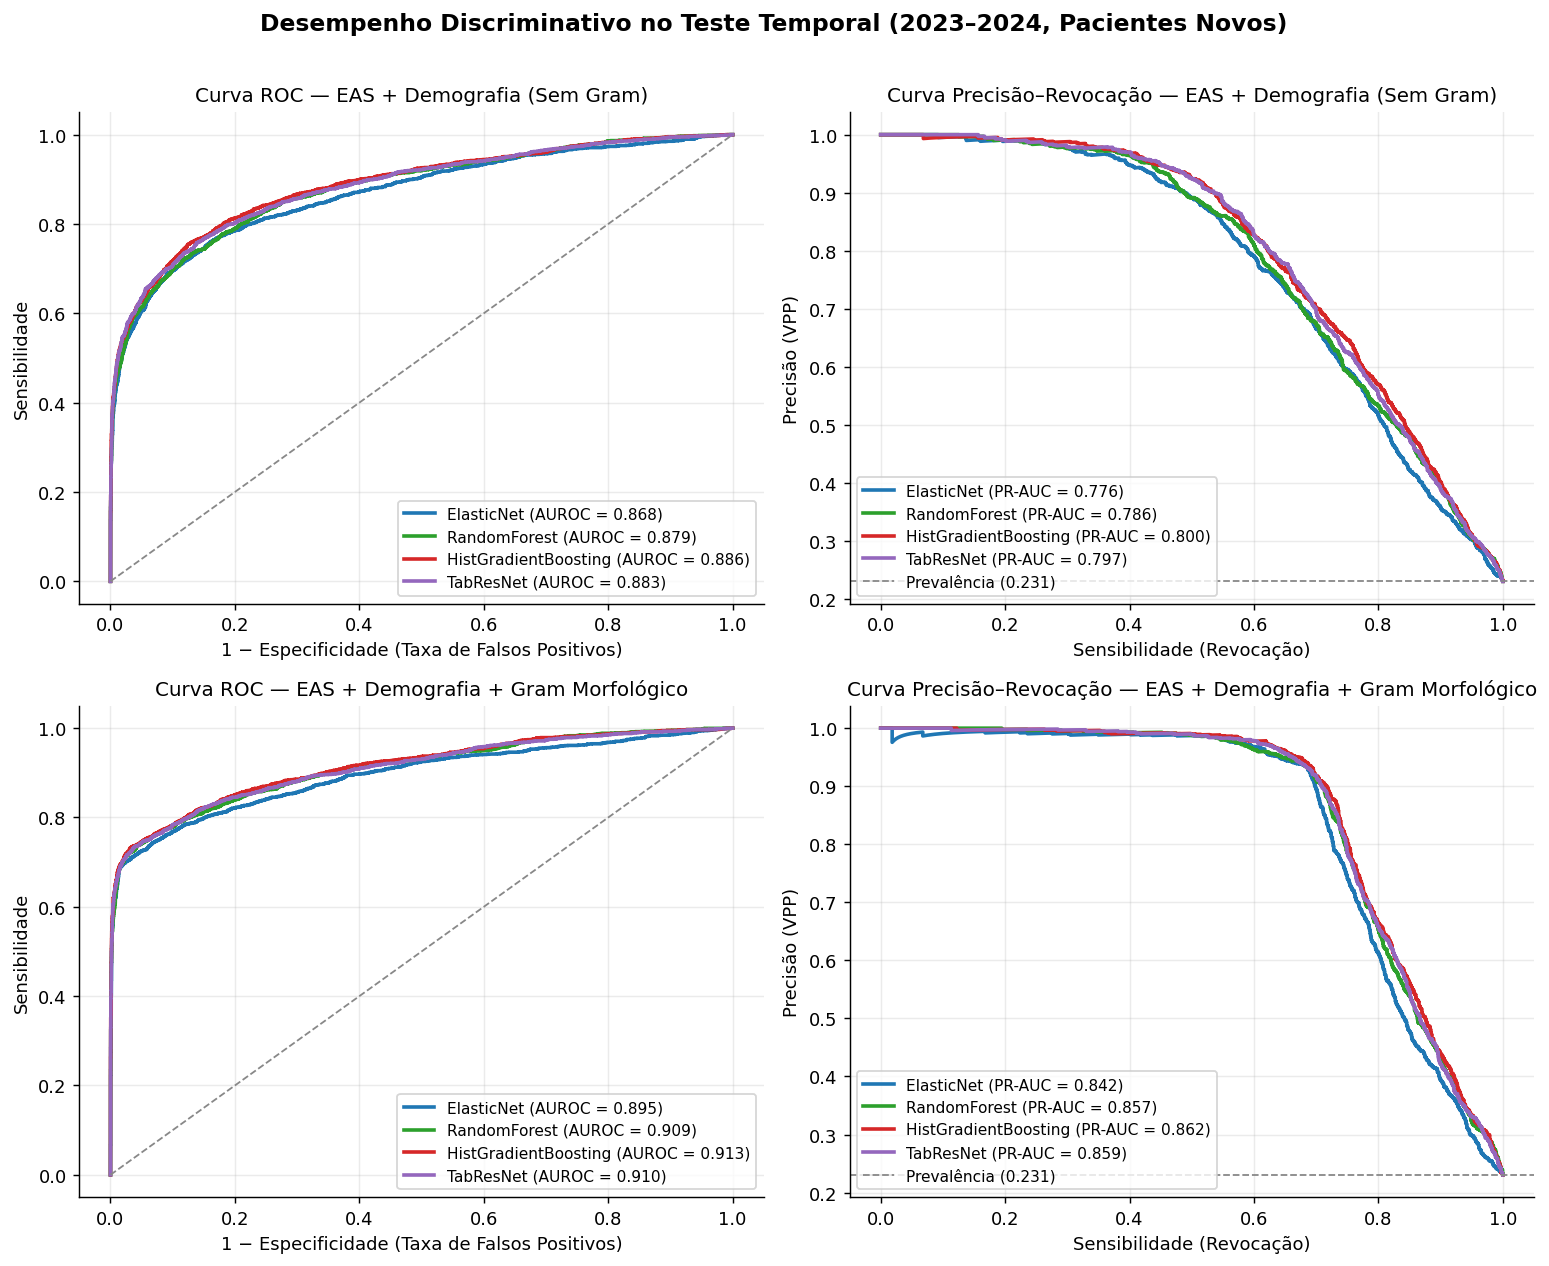

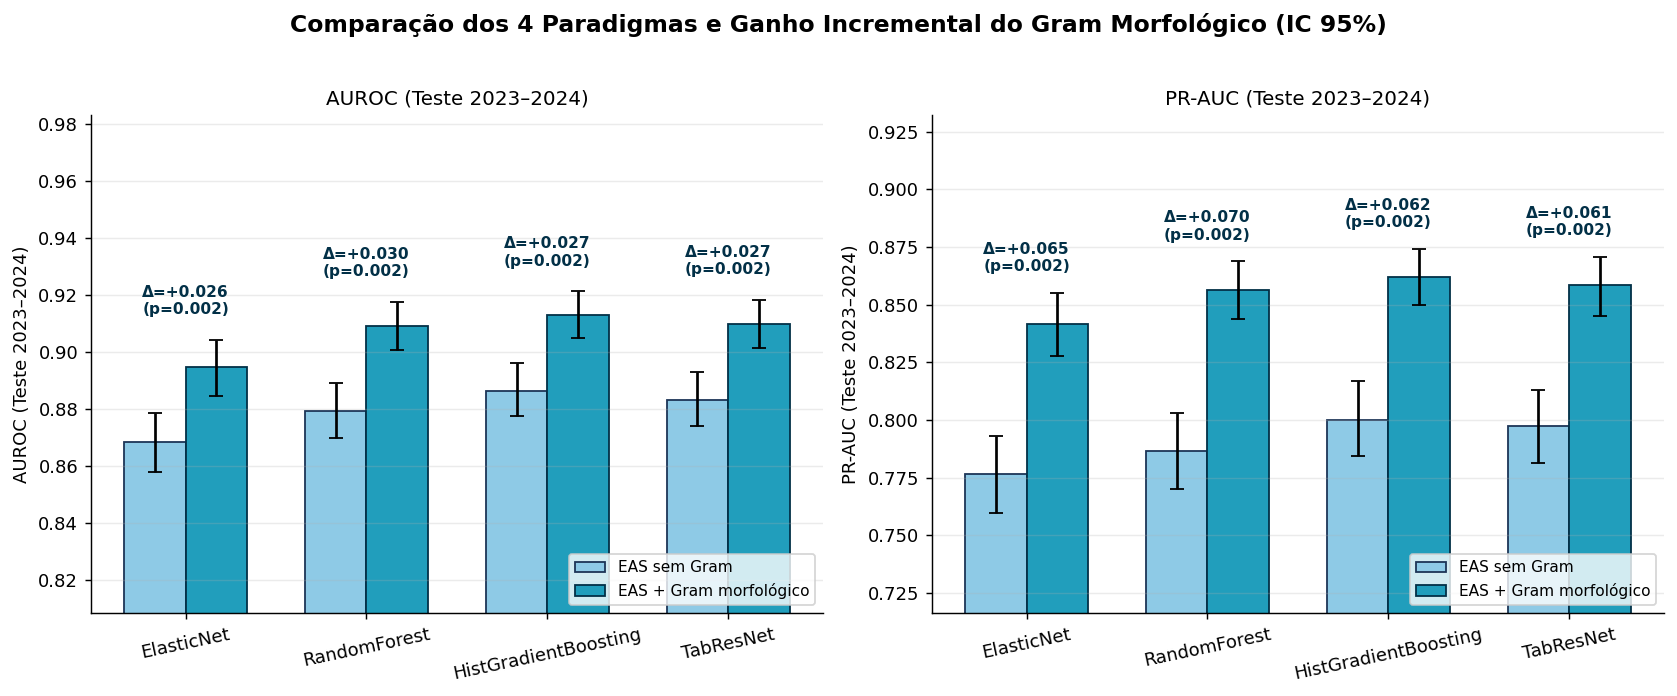

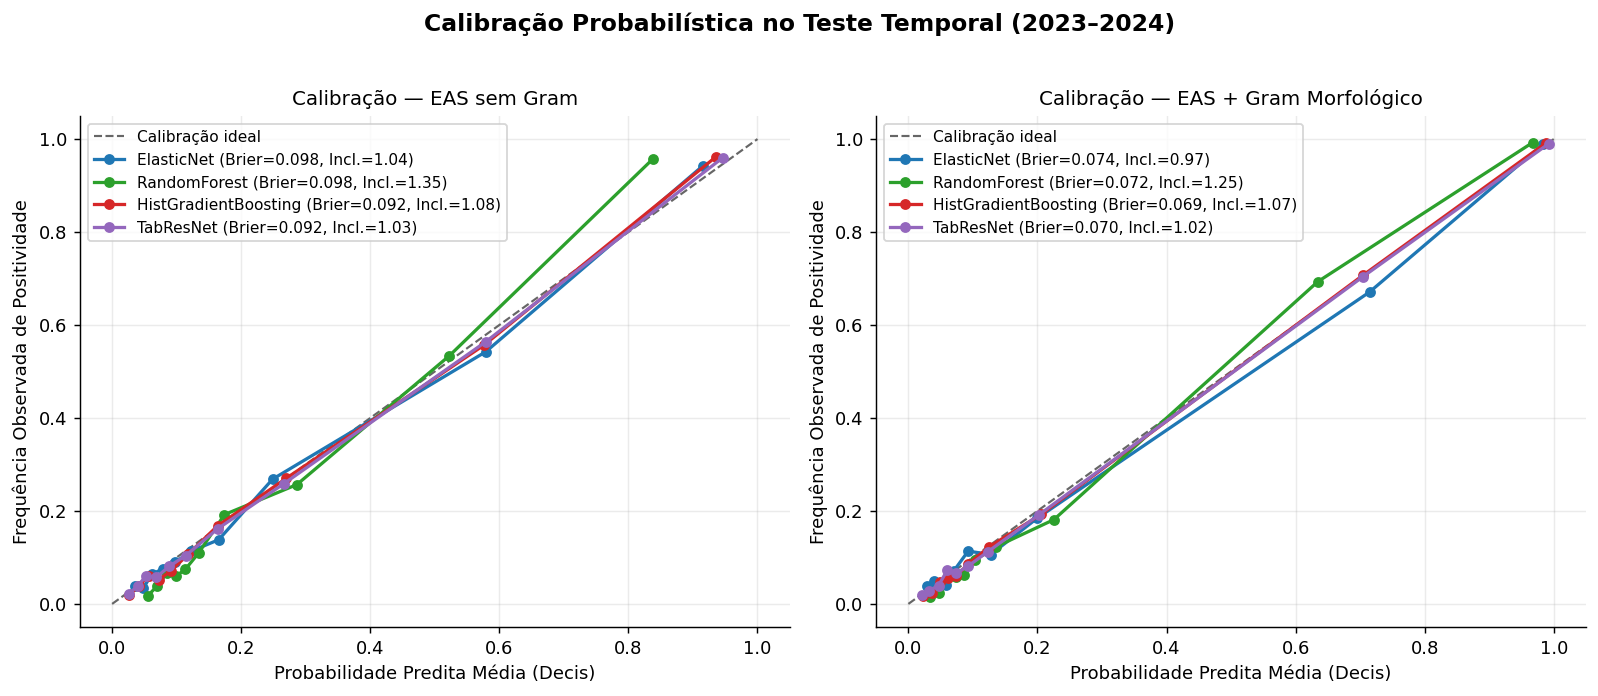

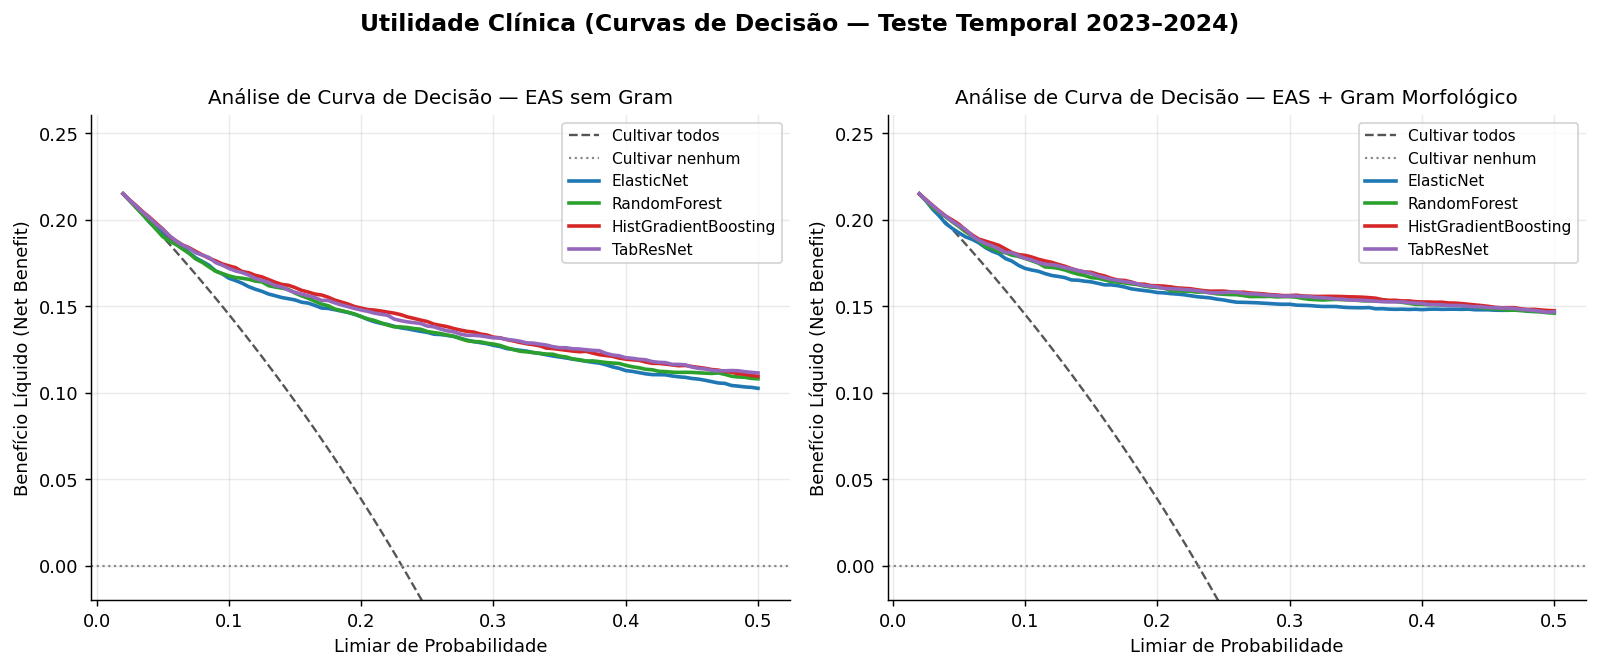

[02:35:58] [EAS_SEM_GRAM] Gerando gráficos de explicabilidade para o modelo líder: HistGradientBoosting...


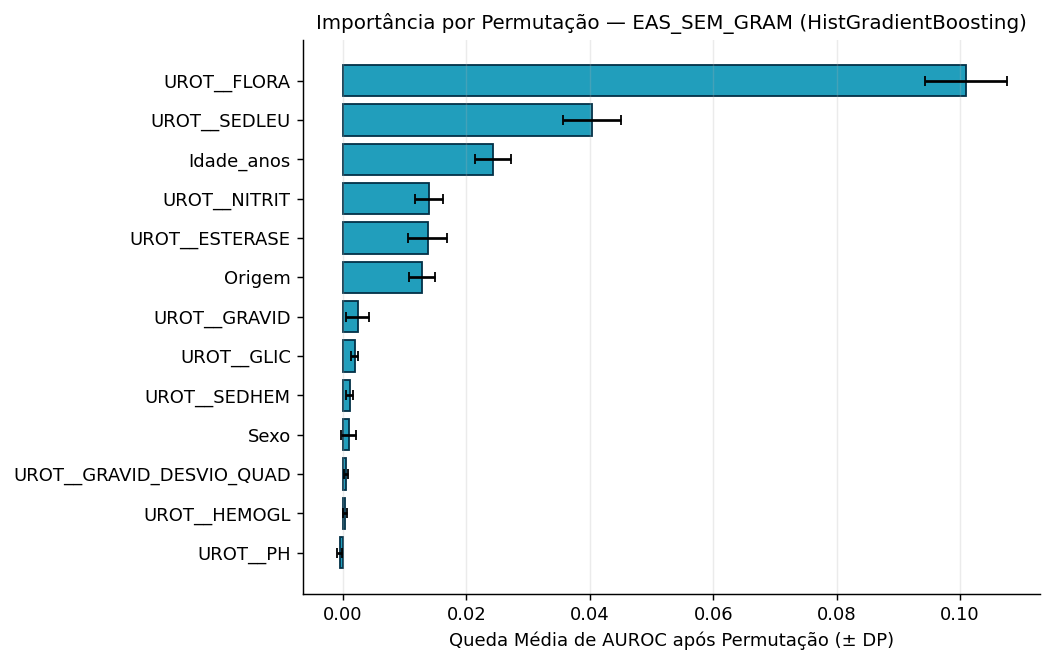

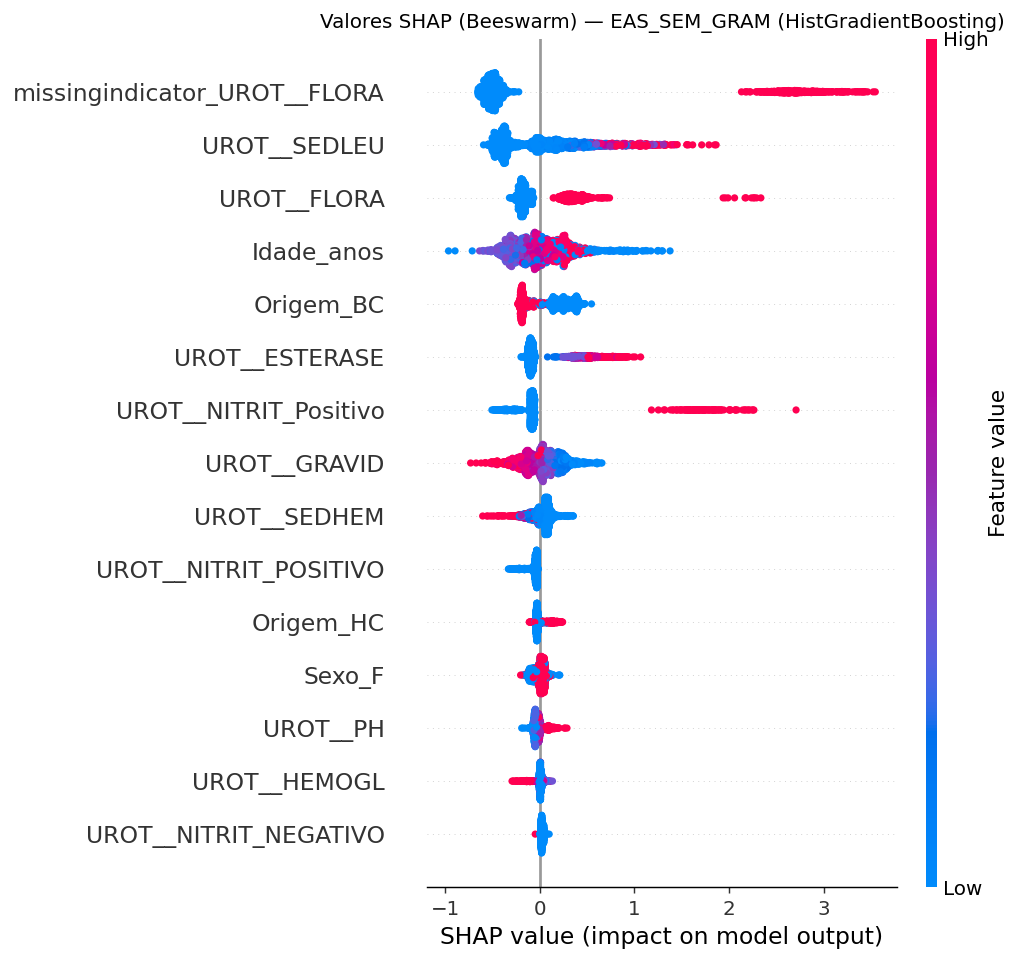

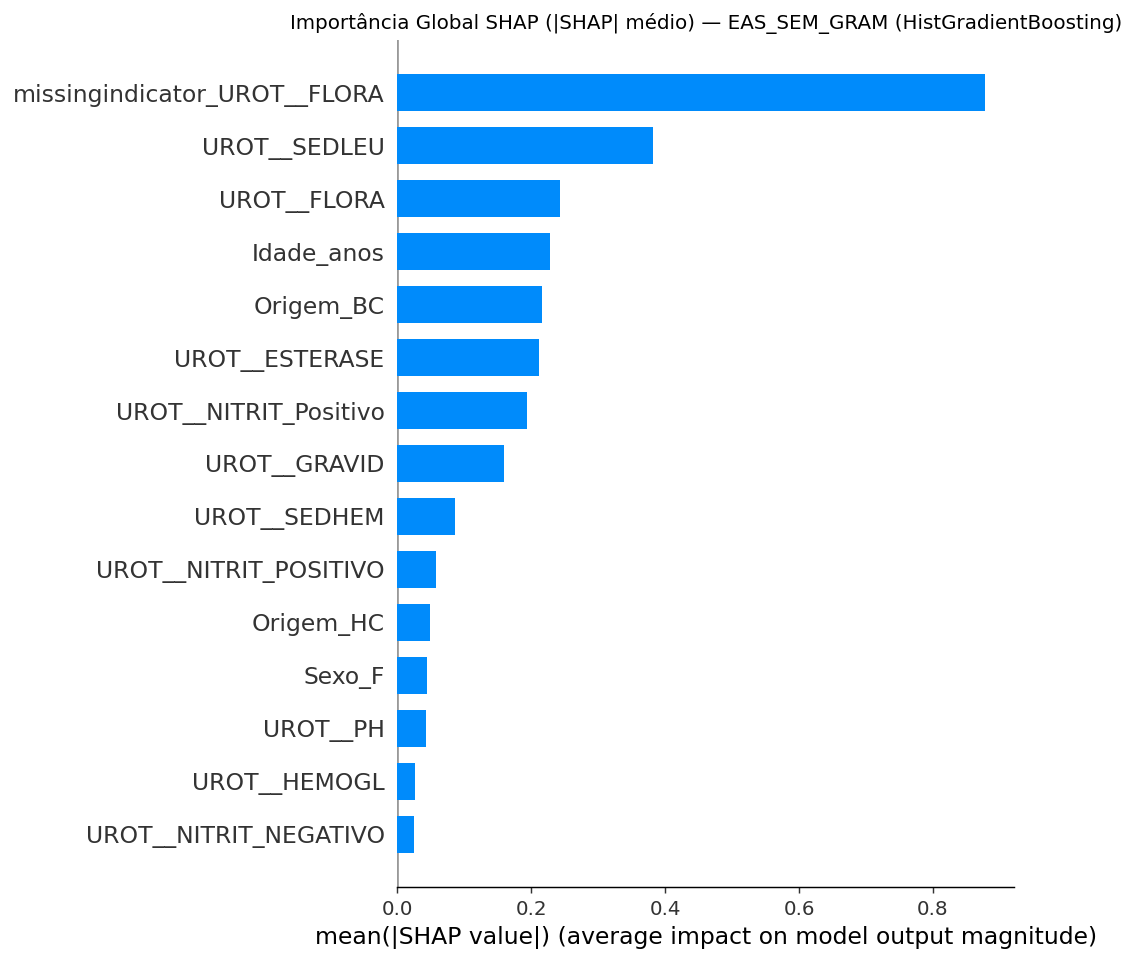

[02:36:18]   Gráficos e tabela SHAP salvos para EAS_SEM_GRAM / HistGradientBoosting.
[02:36:18] [EAS_COM_GRAM] Gerando gráficos de explicabilidade para o modelo líder: HistGradientBoosting...


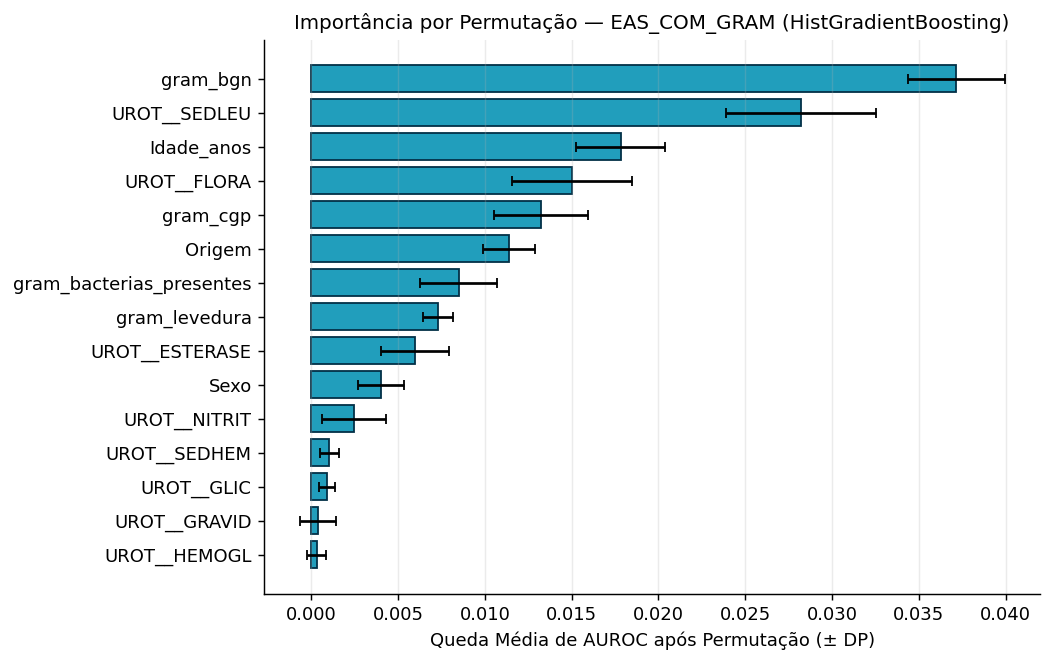

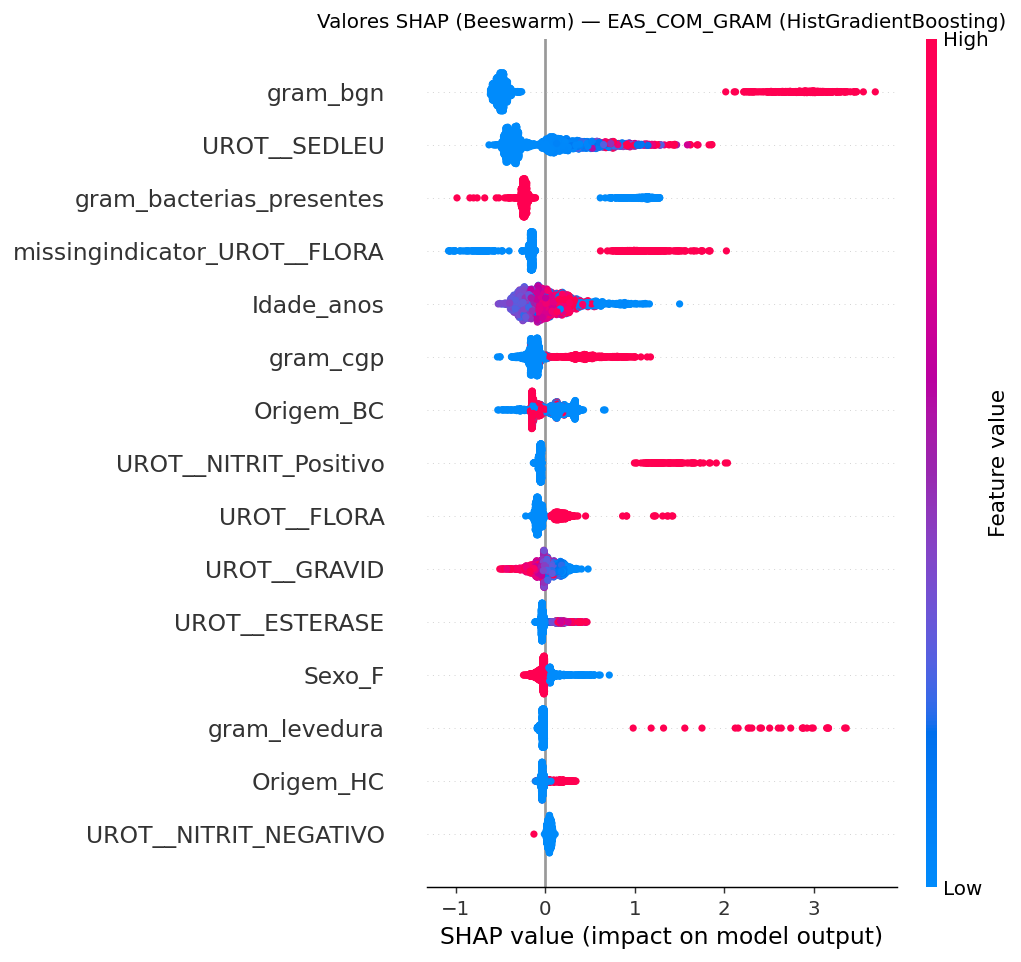

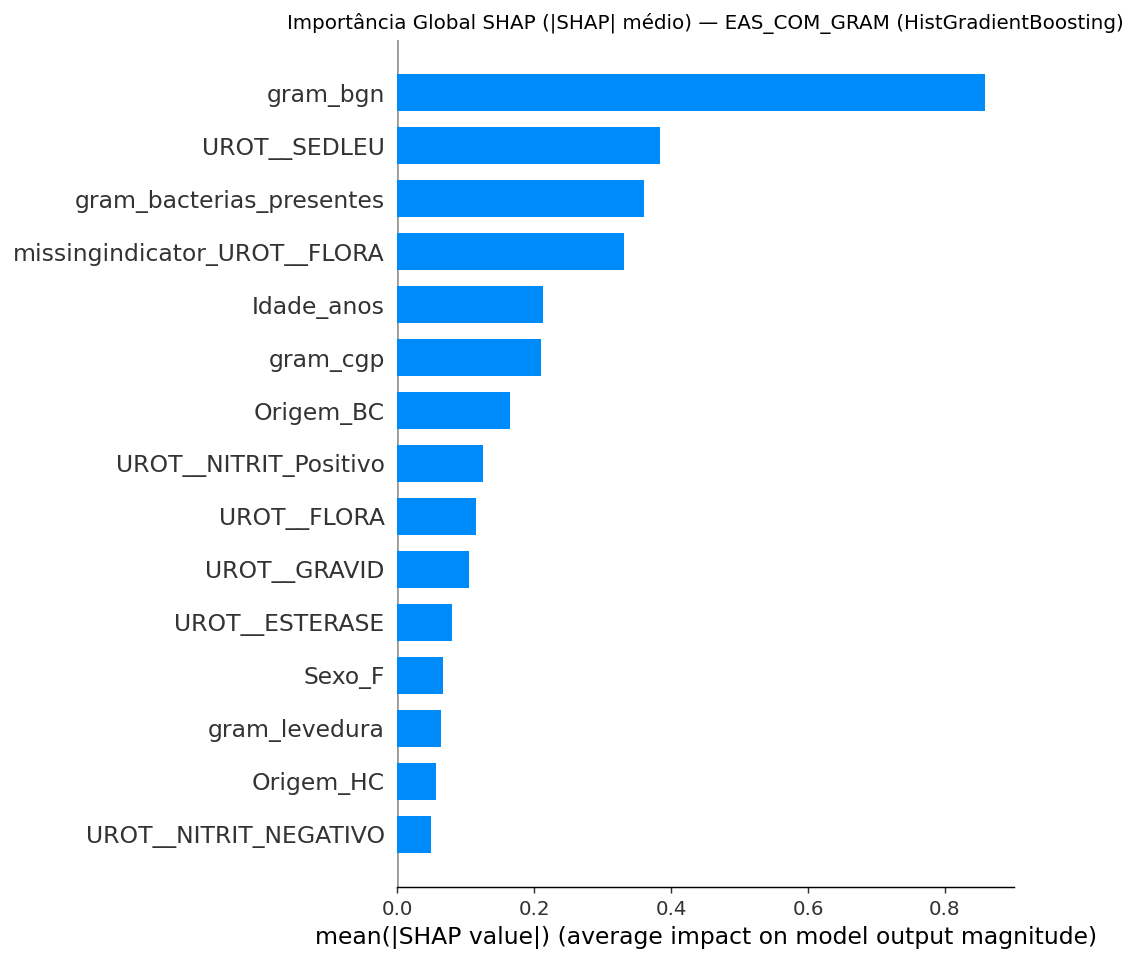

[02:36:29]   Gráficos e tabela SHAP salvos para EAS_COM_GRAM / HistGradientBoosting.
[02:36:30] Execução concluída! Tabelas e figuras (300 DPI) salvas em: /content/drive/MyDrive/Todos os arquivos GPT/resultados_tese_4paradigmas_2023_2024


In [ ]:
def main():
    drive.mount("/content/drive", force_remount=False)
    log(f"Dispositivo ativo: {CONFIG['device']}")

    out_dir = Path(CONFIG["output_dir"])
    fig_dir = out_dir / "figuras"
    fig_dir.mkdir(parents=True, exist_ok=True)

    log("Carregando base definitiva...")
    df_raw = pd.read_csv(CONFIG["input_path"], sep=CONFIG["sep"], low_memory=False)
    log(f"Arquivo lido: {df_raw.shape[0]:,} linhas x {df_raw.shape[1]} colunas.")

    df, num_base_cols, cat_cols, hemogl_col = preparar_dataframe_base(df_raw, CONFIG)

    dev_df = df[df[CONFIG["col_year"]] <= CONFIG["train_max_year"]].copy().reset_index(drop=True)
    test_mask = df[CONFIG["col_year"]].isin(CONFIG["test_years"])
    if CONFIG["exclude_seen_patients_in_test"]:
        seen_pats = set(dev_df[CONFIG["col_group"]].unique())
        test_mask = test_mask & (~df[CONFIG["col_group"]].isin(seen_pats))
    test_df = df[test_mask].copy().reset_index(drop=True)

    y_dev = dev_df[CONFIG["col_target"]].to_numpy()
    g_dev = dev_df[CONFIG["col_group"]].to_numpy()
    y_test = test_df[CONFIG["col_target"]].to_numpy()
    g_test = test_df[CONFIG["col_group"]].to_numpy()

    log(
        f"Split Temporal | Treino (<=2022): n={len(dev_df):,} ({dev_df[CONFIG['col_group']].nunique():,} pac, prev={y_dev.mean()*100:.2f}%) | "
        f"Teste (2023-2024 novos): n={len(test_df):,} ({test_df[CONFIG['col_group']].nunique():,} pac, prev={y_test.mean()*100:.2f}%)"
    )

    model_specs = get_model_specs(CONFIG["random_state"], CONFIG["device"])
    outer_sgkf = StratifiedGroupKFold(n_splits=CONFIG["outer_splits"])

    audit_log = {
        "config": CONFIG,
        "hemoglobina_col_detectada": hemogl_col,
        "cohort_counts": {
            "dev_n_rows": int(len(dev_df)),
            "dev_n_patients": int(dev_df[CONFIG["col_group"]].nunique()),
            "dev_pos_rate": float(np.mean(y_dev)),
            "test_n_rows": int(len(test_df)),
            "test_n_patients": int(test_df[CONFIG["col_group"]].nunique()),
            "test_pos_rate": float(np.mean(y_test)),
        },
        "arms": {},
        "paired_comparisons_gram_vs_no_gram": {},
    }

    summary_rows = []
    test_probs_store = {}
    fitted_pipes = {}
    perm_tables = []
    shap_tables = []

    for arm in CONFIG["arms"]:
        arm_name = arm["name"]
        incluir_gram = arm["incluir_gram"]
        num_cols = num_base_cols + (GRAM_STRUCTURED_FEATURES if incluir_gram else [])
        feature_cols = num_cols + cat_cols

        log("#" * 76)
        log(f"INICIANDO BRAÇO: {arm_name} ({len(feature_cols)} preditores)")
        log(f"  Numéricos ({len(num_cols)}): {num_cols}")
        log(f"  Categóricos ({len(cat_cols)}): {cat_cols}")

        X_dev = dev_df[feature_cols]
        X_test = test_df[feature_cols]

        audit_log["arms"][arm_name] = {
            "features": {"numeric": num_cols, "categorical": cat_cols},
            "models": {},
        }
        test_probs_store[arm_name] = {}
        fitted_pipes[arm_name] = {}

        for model_name, spec in model_specs.items():
            log("=" * 72)
            log(f"[{arm_name}] Executando paradigma: {model_name}")
            outer_records = []
            outer_oof_probs = np.zeros(len(y_dev), dtype=float)
            outer_oof_mask = np.zeros(len(y_dev), dtype=bool)
            selected_params_list = []

            for fold_idx, (tr_idx, va_idx) in enumerate(outer_sgkf.split(X_dev, y_dev, g_dev), start=1):
                t0_fold = time.perf_counter()
                best_params, inner_youden_th, inner_candidates = select_best_params_inner_cv(
                    X_train_sub=X_dev.iloc[tr_idx],
                    y_train_sub=y_dev[tr_idx],
                    groups_train_sub=g_dev[tr_idx],
                    num_cols=num_cols,
                    cat_cols=cat_cols,
                    spec=spec,
                    inner_splits=CONFIG["inner_splits"],
                )

                prep = build_preprocessor(num_cols, cat_cols, scale_numeric=spec["scale_numeric"])
                clf = spec["estimator_fn"](best_params)
                pipe = Pipeline([("prep", prep), ("model", clf)])
                pipe.fit(X_dev.iloc[tr_idx], y_dev[tr_idx])

                va_probs = pipe.predict_proba(X_dev.iloc[va_idx])[:, 1]
                outer_oof_probs[va_idx] = va_probs
                outer_oof_mask[va_idx] = True

                fold_youden = compute_youden_threshold(y_dev[va_idx], va_probs)
                fold_auroc = float(roc_auc_score(y_dev[va_idx], va_probs))
                fold_prauc = float(average_precision_score(y_dev[va_idx], va_probs))
                elapsed_fold = float(time.perf_counter() - t0_fold)
                selected_params_list.append(best_params)

                outer_records.append({
                    "outer_fold": fold_idx,
                    "best_params": best_params,
                    "inner_oof_youden_threshold": float(inner_youden_th),
                    "outer_fold_youden_threshold": float(fold_youden["threshold"]),
                    "outer_fold_auroc": fold_auroc,
                    "outer_fold_pr_auc": fold_prauc,
                    "fold_seconds": elapsed_fold,
                    "inner_candidates": inner_candidates,
                })
                log(
                    f"  Dobra {fold_idx}/{CONFIG['outer_splits']} ({elapsed_fold:.1f}s) | "
                    f"AUROC={fold_auroc:.4f} | PR-AUC={fold_prauc:.4f} | params={best_params}"
                )

            param_json_counts = {}
            for p in selected_params_list:
                key = json.dumps(p, sort_keys=True)
                param_json_counts[key] = param_json_counts.get(key, 0) + 1
            consolidated_params = json.loads(max(param_json_counts.items(), key=lambda kv: kv[1])[0])

            dev_oof_youden = compute_youden_threshold(y_dev[outer_oof_mask], outer_oof_probs[outer_oof_mask])
            dev_oof_hs95 = compute_high_sensitivity_threshold(
                y_dev[outer_oof_mask], outer_oof_probs[outer_oof_mask], target_sens=CONFIG["target_high_sens"]
            )

            final_prep = build_preprocessor(num_cols, cat_cols, scale_numeric=spec["scale_numeric"])
            final_clf = spec["estimator_fn"](consolidated_params)
            final_pipe = Pipeline([("prep", final_prep), ("model", final_clf)])

            t0_fit = time.perf_counter()
            final_pipe.fit(X_dev, y_dev)
            fit_seconds = float(time.perf_counter() - t0_fit)

            t0_inf = time.perf_counter()
            test_probs = final_pipe.predict_proba(X_test)[:, 1]
            infer_seconds = float(time.perf_counter() - t0_inf)

            test_eval = evaluate_with_grouped_bootstrap(
                y_true=y_test,
                y_prob=test_probs,
                groups=g_test,
                threshold_youden=dev_oof_youden["threshold"],
                threshold_hs95=dev_oof_hs95["threshold"],
                n_bootstrap=CONFIG["n_bootstrap"],
                seed=CONFIG["random_state"],
            )

            test_probs_store[arm_name][model_name] = test_probs
            fitted_pipes[arm_name][model_name] = (final_pipe, X_test)

            log(
                f"  -> FINAL [{arm_name}] {model_name}: AUROC={test_eval['auroc']:.4f} | "
                f"PR-AUC={test_eval['pr_auc']:.4f} | Brier={test_eval['brier_score']:.4f} | "
                f"HS95 Sens={test_eval['hs95_sensitivity']:.4f} / Evitáveis={test_eval['hs95_pct_cultures_avoided']*100:.1f}%"
            )

            audit_log["arms"][arm_name]["models"][model_name] = {
                "consolidated_params": consolidated_params,
                "params_frequency_across_outer_folds": param_json_counts,
                "dev_oof_youden_summary": dev_oof_youden,
                "dev_oof_hs95_summary": dev_oof_hs95,
                "fit_seconds_full_dev": fit_seconds,
                "infer_seconds_test_2023_2024": infer_seconds,
                "outer_folds_detail": outer_records,
                "test_2023_2024_metrics": test_eval,
            }

            summary_rows.append({
                "arm": arm_name,
                "model": model_name,
                "youden_th_dev": dev_oof_youden["threshold"],
                "hs95_th_dev": dev_oof_hs95["threshold"],
                "test_auroc": test_eval["auroc"],
                "test_auroc_ci95_low": test_eval["auroc_ci95_low"],
                "test_auroc_ci95_high": test_eval["auroc_ci95_high"],
                "test_pr_auc": test_eval["pr_auc"],
                "test_pr_auc_ci95_low": test_eval["pr_auc_ci95_low"],
                "test_pr_auc_ci95_high": test_eval["pr_auc_ci95_high"],
                "test_brier": test_eval["brier_score"],
                "test_cal_slope": test_eval["calibration_slope"],
                "test_cal_intercept": test_eval["calibration_intercept"],
                "youden_sens": test_eval["sensitivity"],
                "youden_spec": test_eval["specificity"],
                "youden_ppv": test_eval["ppv"],
                "youden_npv": test_eval["npv"],
                "hs95_sens": test_eval["hs95_sensitivity"],
                "hs95_spec": test_eval["hs95_specificity"],
                "hs95_npv": test_eval["hs95_npv"],
                "hs95_pct_avoided": test_eval["hs95_pct_cultures_avoided"],
                "hs95_missed_pos_per_1000": test_eval["hs95_missed_pos_per_1000"],
                "fit_seconds": fit_seconds,
                "infer_seconds": infer_seconds,
                "consolidated_params_json": json.dumps(consolidated_params, sort_keys=True),
            })

    summary_df = pd.DataFrame(summary_rows)

    paired_rows = []
    if "EAS_COM_GRAM" in test_probs_store and "EAS_SEM_GRAM" in test_probs_store:
        log("=" * 72)
        log("Comparação pareada (EAS_COM_GRAM vs. EAS_SEM_GRAM) por bootstrap agrupado:")
        for model_name in model_specs.keys():
            comp = paired_bootstrap_comparison(
                y_true=y_test,
                prob_a=test_probs_store["EAS_COM_GRAM"][model_name],
                prob_b=test_probs_store["EAS_SEM_GRAM"][model_name],
                groups=g_test,
                n_bootstrap=CONFIG["n_bootstrap"],
                seed=CONFIG["random_state"],
            )
            audit_log["paired_comparisons_gram_vs_no_gram"][model_name] = comp
            paired_rows.append({
                "model": model_name,
                "delta_auroc": comp["delta_auroc"]["delta"],
                "delta_auroc_ci95_low": comp["delta_auroc"]["ci95_low"],
                "delta_auroc_ci95_high": comp["delta_auroc"]["ci95_high"],
                "delta_auroc_p": comp["delta_auroc"]["p_bootstrap_bilateral"],
                "delta_pr_auc": comp["delta_pr_auc"]["delta"],
                "delta_pr_auc_ci95_low": comp["delta_pr_auc"]["ci95_low"],
                "delta_pr_auc_ci95_high": comp["delta_pr_auc"]["ci95_high"],
                "delta_pr_auc_p": comp["delta_pr_auc"]["p_bootstrap_bilateral"],
                "delta_brier": comp["delta_brier"]["delta"],
                "delta_brier_ci95_low": comp["delta_brier"]["ci95_low"],
                "delta_brier_ci95_high": comp["delta_brier"]["ci95_high"],
                "delta_brier_p": comp["delta_brier"]["p_bootstrap_bilateral"],
            })
    paired_df = pd.DataFrame(paired_rows)

    # Salva CSVs, predições e JSON de auditoria
    summary_df.to_csv(out_dir / "summary_models_2023_2024.csv", index=False)
    paired_df.to_csv(out_dir / "comparacao_pareada_gram_2023_2024.csv", index=False)

    pred_df = pd.DataFrame({
        CONFIG["col_group"]: g_test,
        CONFIG["col_year"]: test_df[CONFIG["col_year"]].to_numpy(),
        CONFIG["col_target"]: y_test,
    })
    for arm_name, mdict in test_probs_store.items():
        for model_name, probs in mdict.items():
            pred_df[f"prob__{arm_name}__{model_name}"] = probs
    pred_df.to_csv(out_dir / "predicoes_teste_2023_2024.csv.gz", index=False, compression="gzip")

    with open(out_dir / "audit_full_log.json", "w", encoding="utf-8") as f:
        json.dump(audit_log, f, indent=2, ensure_ascii=False)

    # Exibe tabelas formatadas direto na saída do Colab
    print("\n=== TABELA 1: DESEMPENHO DOS 4 PARADIGMAS NO TESTE TEMPORAL (2023–2024) ===")
    display(summary_df)
    print("\n=== TABELA 2: GANHO INCREMENTAL DO GRAM MORFOLÓGICO (COM GRAM − SEM GRAM) ===")
    display(paired_df)

    # Gera e exibe todos os gráficos acadêmicos em 300 DPI
    plot_roc_pr_curves(y_test, test_probs_store, fig_dir)
    if len(paired_df) > 0:
        plot_gram_gain_comparison(summary_df, paired_df, fig_dir)
    plot_calibration_curves(y_test, test_probs_store, summary_df, fig_dir)
    plot_decision_curve_analysis(y_test, test_probs_store, fig_dir)

    # Explicabilidade (Permutação + SHAP) para o modelo líder de cada braço
    for arm in CONFIG["arms"]:
        arm_name = arm["name"]
        arm_sub = summary_df[summary_df["arm"] == arm_name]
        best_model_name = arm_sub.loc[arm_sub["test_auroc"].idxmax(), "model"]
        best_pipe, X_test_best = fitted_pipes[arm_name][best_model_name]
        log(f"[{arm_name}] Gerando gráficos de explicabilidade para o modelo líder: {best_model_name}...")
        p_df, s_df = compute_and_plot_explainability(
            best_pipe, X_test_best, y_test, out_dir, fig_dir, arm_name, best_model_name,
            sample_size=CONFIG["shap_sample_size"], seed=CONFIG["random_state"],
        )
        perm_tables.append(p_df)
        if s_df is not None:
            shap_tables.append(s_df)

    # Exporta planilha Excel consolidada multi-abas para fácil consulta e inclusão na tese
    xlsx_path = out_dir / "Tabelas_Consolidadas_2023_2024.xlsx"
    with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
        summary_df.to_excel(writer, sheet_name="Resumo_4_Paradigmas", index=False)
        paired_df.to_excel(writer, sheet_name="Ganho_Gram_Pareado", index=False)
        if perm_tables:
            pd.concat(perm_tables, ignore_index=True).to_excel(writer, sheet_name="Importancia_Permutacao", index=False)
        if shap_tables:
            pd.concat(shap_tables, ignore_index=True).to_excel(writer, sheet_name="SHAP_Resumo", index=False)

    log(f"Execução concluída! Tabelas e figuras (300 DPI) salvas em: {out_dir}")


if __name__ == "__main__":
    main()
